In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import tt_ind_solve_power

pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 50)

ab_data = pd.read_csv('/home/art/olist_data/ab_data.csv')

print("Данные загружены")
print("Размер:", ab_data.shape)
ab_data.head()

Данные загружены
Размер: (294478, 5)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [2]:
print("Группы:")
print(ab_data['group'].value_counts())
print()
print("Страницы:")
print(ab_data['landing_page'].value_counts())

Группы:
group
treatment    147276
control      147202
Name: count, dtype: int64

Страницы:
landing_page
old_page    147239
new_page    147239
Name: count, dtype: int64


In [3]:
conversion = ab_data.groupby('group')['converted'].mean().round(4)
print("Конверсия по группам:")
print(conversion)

Конверсия по группам:
group
control      0.1204
treatment    0.1189
Name: converted, dtype: float64


In [4]:
conversion_page = ab_data.groupby('landing_page')['converted'].mean().round(4)
print("Конверсия по страницам:")
print(conversion_page)

Конверсия по страницам:
landing_page
new_page    0.1188
old_page    0.1205
Name: converted, dtype: float64


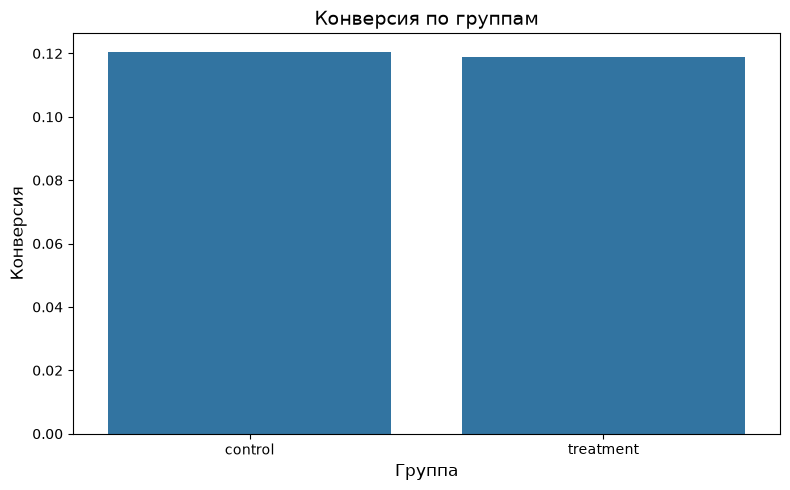

In [16]:
plt.figure(figsize = (8,5))
sns.barplot(x='group', y = 'converted', data=ab_data, errorbar = None)
plt.title('Конверсия по группам', fontsize = 14)
plt.xlabel('Группа', fontsize = 12)
plt.ylabel('Конверсия', fontsize = 12)
plt.tight_layout()
plt.savefig('conversion_chart.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
control = ab_data[ab_data['group'] == 'control']['converted']
treatment = ab_data[ab_data['group'] == 'treatment']['converted']

t_stat, p_value = stats.ttest_ind(treatment, control)

print(f"Средняя конверсия в treatment: {treatment.mean():.4f}")
print(f"Средняя конверсия в control:   {control.mean():.4f}")
print(f"Разница:                       {treatment.mean() - control.mean():.4f}")
print(f"t-статистика:                  {t_stat:.4f}")
print(f"p-value:                       {p_value:.4f}")

Средняя конверсия в treatment: 0.1189
Средняя конверсия в control:   0.1204
Разница:                       -0.0015
t-статистика:                  -1.2369
p-value:                       0.2161


In [10]:
def conf_interval (data, confidence = 0.95):
    n = len(data)
    mean = np.mean(data)
    se = stats.sem(data)
    h = se * stats.t.ppf((1 + confidence) / 2, n - 1)
    return  mean - h, mean + h
ci_control = conf_interval(control)
ci_treatment = conf_interval(treatment)

print(f"CI 95% для control: [{ci_control[0]:.4f}, {ci_control[1]:.4f}]")
print(f"CI 95% для treatment: [{ci_treatment[0]:.4f}, {ci_treatment[1]:.4f}]")

CI 95% для control: [0.1187, 0.1221]
CI 95% для treatment: [0.1173, 0.1206]


In [14]:
sample_size = tt_ind_solve_power(
    effect_size = 0.1,
    alpha = 0.05,
    power = 0.8,
    ratio = 1
)

print(f"Нужный размер выборки для каждой группы: {int(sample_size)}")
print(f"Всего нужно пользователей: {int(sample_size) * 2}")

Нужный размер выборки для каждой группы: 1570
Всего нужно пользователей: 3140


In [15]:
alpha = 0.05

if p_value < alpha:
    print("Разница статистически значима. Можно внедрять.")
else:
    print("Разница НЕ значима. Нельзя утверждать, что новая версия лучше.")

Разница НЕ значима. Нельзя утверждать, что новая версия лучше.
